# TCGA-GBM RNA-seq Analysis: Quality Control

**Ola Hassan, PhD**

## Introduction

This notebook evaluates the count matrix prepared in Notebook 1 "Build count maretix" before differential expression analysis. Quality control includes assessing library sizes, filtering low-count genes, and exploring sample relationships using PCA and hierarchical clustering.

These analyses help identify variation in sequencing depth and samples with unusual expression patterns. Sample clustering is examined alongside tumor/normal condition labels to assess whether tissue condition contributes to the observed variation.

Raw counts are retained for downstream analysis with PyDESeq2. Transformed expression values are used only for exploratory visualization.

## Objectives

- Verify count-matrix structure and alignment with sample metadata.
- Assess library sizes across samples.
- Remove non-gene summary rows and filter low-count genes.
- Explore sample relationships using PCA and hierarchical clustering.
- Investigate potential outliers before deciding whether any samples should be excluded.
- Export the filtered raw count matrix and aligned metadata.

In [1]:
#Import packages:

from pathlib import Path
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from scipy.cluster.hierarchy import dendrogram, linkage

To get and copy the path of a folder:

Method 1: Drag and Drop Open Finder. Find the folder you want. Open Terminal. Drag the folder from Finder into the Terminal window.

Method 2: Copy Pathname In Finder, right-click the folder. Hold the Option (⌥) key. You'll see "Copy 'FolderName' as Pathname"

## 1- Define notebook paths

Library size is calculated as the sum of raw gene counts for each sample. Comparing these totals helps identify differences in sequencing depth and samples that may require further investigation.

In [4]:
# Define project folders
PROJECT = Path("/Users/olahassan/Desktop/Python/TCGA_GBM")
DATA = PROJECT / "data_processed"
FIGURES = PROJECT / "Figures"

FIGURES.mkdir(parents=True, exist_ok=True)

# Load inputs from Notebook 1
counts = pd.read_csv(
    DATA / "count_matrix_ensembl.csv",
    index_col=0
)

metadata = pd.read_csv(
    DATA / "metadata.csv",
    index_col=0
)

# Check identifier uniqueness
assert counts.index.is_unique, "Duplicate gene identifiers found."
assert counts.columns.is_unique, "Duplicate sample identifiers found."
assert metadata.index.is_unique, "Duplicate metadata sample identifiers found."

# Verify that counts and metadata contain the same samples
assert set(counts.columns) == set(metadata.index), (
    "Sample identifiers differ between counts and metadata."
)

# Align metadata to the count-matrix column order
metadata = metadata.loc[counts.columns].copy()

assert metadata.index.equals(counts.columns)
assert "condition" in metadata.columns, "Missing condition column."
assert metadata["condition"].notna().all(), "Missing condition labels."

# Verify that counts are numeric, finite, nonnegative integers
counts = counts.apply(pd.to_numeric, errors="raise")

assert np.isfinite(counts.to_numpy()).all(), "Missing or infinite counts."
assert (counts >= 0).all().all(), "Negative counts found."
assert (counts == np.floor(counts)).all().all(), (
    "Input must contain raw integer counts."
)

counts = counts.astype("int64")

# Retain Ensembl gene rows; exclude STAR summary rows
counts = counts.loc[
    counts.index.astype(str).str.startswith("ENSG")
].copy()

assert not counts.empty, "No Ensembl gene rows found."
assert (counts.sum(axis=0) > 0).all(), "A sample has zero total gene counts."

# Summarize inputs
print(f"Genes: {counts.shape[0]:,}")
print(f"Samples: {counts.shape[1]}")
print("\nSamples per condition:")
print(metadata["condition"].value_counts())

Genes: 59,427
Samples: 10

Samples per condition:
condition
Tumor     5
Normal    5
Name: count, dtype: int64


## 2- Assess Library Sizes

Library size is calculated as the sum of raw gene counts for each sample. Comparing these totals helps identify differences in sequencing depth and samples that may require further investigation.

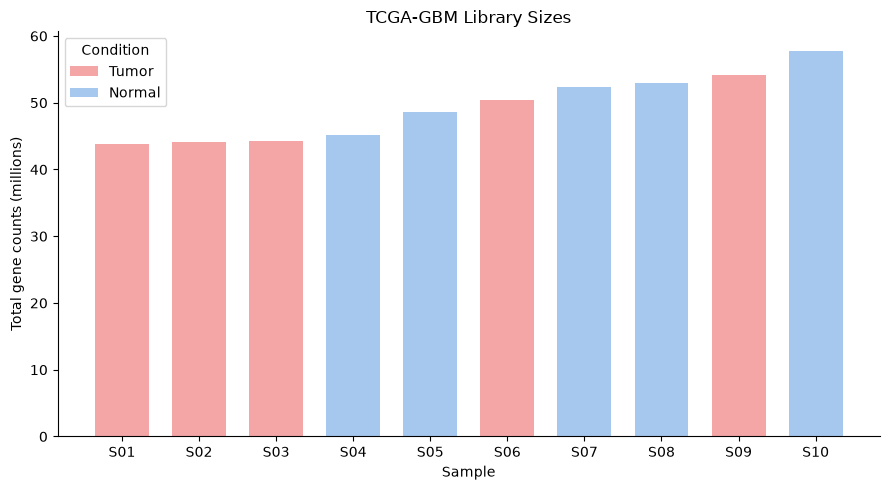

,condition,library_size,plot_label
afbd1975-263b-404b-a738-886bf25c0223,Tumor,43766288,S01
99ff2016-a97a-4142-b70a-1bb59d6264e9,Tumor,44047608,S02
444a2332-9e52-4cf8-94d9-07a8b829633e,Tumor,44278924,S03
477a4ae1-84c0-49f2-b3b3-4015b8c26f18,Normal,45164502,S04
ddaed459-ab19-4f75-a1a9-72761287c6f5,Normal,48656675,S05
d4649bc7-09d2-4d90-bafd-0bec72429b00,Tumor,50346014,S06
c410d37e-e445-4f5f-8937-e6796dd52364,Normal,52370060,S07
4bed9101-07f4-4d76-b79f-6eb8de04bd19,Normal,53015405,S08
77c261f0-384c-4906-a57e-7c3b35c17041,Tumor,54179163,S09
64a2ddbe-3614-409a-af16-170a1471db2a,Normal,57807042,S10


Largest-to-smallest library-size ratio: 1.32


In [8]:
from matplotlib.patches import Patch

# Total gene counts per sample
library_size = counts.sum(axis=0)

library_df = metadata[["condition"]].copy()
library_df["library_size"] = library_size
library_df = library_df.sort_values("library_size")

colors = {
     "Tumor": "#F4A6A6",   # Pastel red
    "Normal": "#A6C8EE"   # Pastel blue
}

# Use short labels while retaining full IDs in the table
library_df["plot_label"] = [
    f"S{i + 1:02d}" for i in range(len(library_df))
]

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    library_df["plot_label"],
    library_df["library_size"] / 1_000_000,
    color=library_df["condition"].map(colors),
    width=0.7
)

ax.set_xlabel("Sample")
ax.set_ylabel("Total gene counts (millions)")
ax.set_title("TCGA-GBM Library Sizes")
ax.spines[["top", "right"]].set_visible(False)

ax.legend(
    handles=[
        Patch(facecolor=color, label=condition)
        for condition, color in colors.items()
    ],
    title="Condition"
)

fig.tight_layout()
fig.savefig(
    FIGURES / "QC_Library_Sizes.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Display full sample IDs and their plot labels
display(library_df)

print(
    "Largest-to-smallest library-size ratio: "
    f"{library_size.max() / library_size.min():.2f}"
)

### Library Size Assessment

Total gene counts range from approximately 44 to 58 million per sample, with a largest-to-smallest ratio of approximately 1.3. Tumor and normal samples have overlapping library sizes, and no sample shows a markedly reduced count total.

This check does not identify an obvious library-size outlier. Further assessment will use normalized expression values for PCA and hierarchical clustering.

## 3- Filter Low-Count Genes

Genes with very low counts provide limited information for differential expression analysis. Genes are retained if they have at least 10 raw counts in at least 2 samples.

This filter allows genes expressed primarily in either tumor or normal samples to remain in the analysis. Retained counts remain unnormalized integers for downstream use with PyDESeq2.

In [9]:
# Retain genes with at least 10 counts in at least 2 samples
min_counts = 10
min_samples = 2

keep = (counts >= min_counts).sum(axis=1) >= min_samples
filtered_counts = counts.loc[keep].copy()

# Report filtering results
genes_before = counts.shape[0]
genes_after = filtered_counts.shape[0]

print(f"Genes before filtering: {genes_before:,}")
print(f"Genes retained: {genes_after:,}")
print(f"Genes removed: {genes_before - genes_after:,}")
print(f"Percentage retained: {100 * genes_after / genes_before:.1f}%")
print(f"Samples retained: {filtered_counts.shape[1]}")

Genes before filtering: 59,427
Genes retained: 31,041
Genes removed: 28,386
Percentage retained: 52.2%
Samples retained: 10


### Filtering Summary

Of the 59,427 input genes, 31,041 (52.2%) met the threshold of at least 10 counts in at least 2 samples. The remaining 28,386 genes were excluded because they did not meet this expression threshold.

All 10 samples were retained. The filtered matrix contains raw integer counts for downstream differential expression analysis.

## 4- Explore Sample Relationships

### 4-1 Data Transformation for Visualization

Counts per million (CPM) are calculated using each sample's total gene counts before low-count filtering. The values are then transformed as log2(CPM + 1) to reduce the influence of highly expressed genes.

These transformed values are used for exploratory PCA and clustering. The filtered raw counts are kept separately for PyDESeq2.

In [10]:
# Library totals from all gene rows before low-count filtering
library_totals = counts.sum(axis=0)

# Normalize retained genes to counts per million
cpm = filtered_counts.div(library_totals, axis=1) * 1_000_000

# Log transformation for exploratory visualization
log_cpm = np.log2(cpm + 1)

# PCA and clustering require samples as rows and genes as columns
X = log_cpm.T

assert X.index.equals(metadata.index)
assert np.isfinite(X.to_numpy()).all()

print(f"Visualization matrix: {X.shape[0]} samples × {X.shape[1]:,} genes")

Visualization matrix: 10 samples × 31,041 genes


### 4-2 PCA

PCA summarizes the main sources of variation across samples using log2(CPM + 1) expression values. Samples are colored by condition to examine tumor/normal separation and variation within each group.

The percentage on each axis indicates the proportion of total variance explained by that principal component.

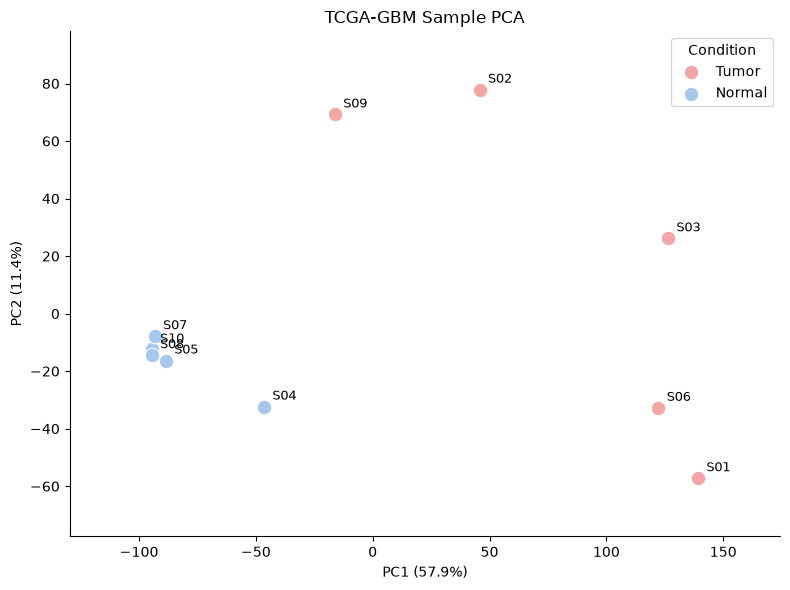

PC1 explains 57.9% of variance
PC2 explains 11.4% of variance


In [11]:
# Run PCA on samples × genes
pca = PCA(n_components=2)
principal_components = pca.fit_transform(X)

pca_df = pd.DataFrame(
    principal_components,
    columns=["PC1", "PC2"],
    index=X.index
).join(metadata[["condition"]])

# Reuse the sample labels from the library-size plot
pca_df["plot_label"] = library_df["plot_label"].reindex(pca_df.index)

colors = {
    "Tumor": "#F4A6A6",
    "Normal": "#A6C8EE"
}

fig, ax = plt.subplots(figsize=(8, 6))

for condition, color in colors.items():
    subset = pca_df[pca_df["condition"] == condition]

    ax.scatter(
        subset["PC1"],
        subset["PC2"],
        color=color,
        label=condition,
        s=110,
        edgecolor="white",
        linewidth=0.8
    )

    for _, row in subset.iterrows():
        ax.annotate(
            row["plot_label"],
            (row["PC1"], row["PC2"]),
            xytext=(6, 5),
            textcoords="offset points",
            fontsize=9
        )

variance = pca.explained_variance_ratio_ * 100

ax.set_xlabel(f"PC1 ({variance[0]:.1f}%)")
ax.set_ylabel(f"PC2 ({variance[1]:.1f}%)")
ax.set_title("TCGA-GBM Sample PCA")
ax.legend(title="Condition")
ax.spines[["top", "right"]].set_visible(False)
ax.margins(0.15)

fig.tight_layout()
fig.savefig(
    FIGURES / "QC_PCA_LogCPM.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print(f"PC1 explains {variance[0]:.1f}% of variance")
print(f"PC2 explains {variance[1]:.1f}% of variance")

### PCA Interpretation

PCA shows separation between tumor and normal samples primarily along PC1. Tumor samples are more dispersed, indicating greater expression variability within the tumor group (very much expected with GBM as a heretogenous tumor)


These patterns are consistent with condition-associated expression differences, although biological and technical factors may both contribute. No samples are excluded based on this PCA alone; hierarchical clustering will provide an additional view of sample relationships.

In [25]:
### 4-3 Hierarchical Clustering

Hierarchical clustering provides another view of sample similarity using log2(CPM + 1) expression values. Samples are grouped using Euclidean distance and Ward linkage.

The dendrogram is examined for tumor/normal grouping and variation within each condition. Sample labels are colored by condition.

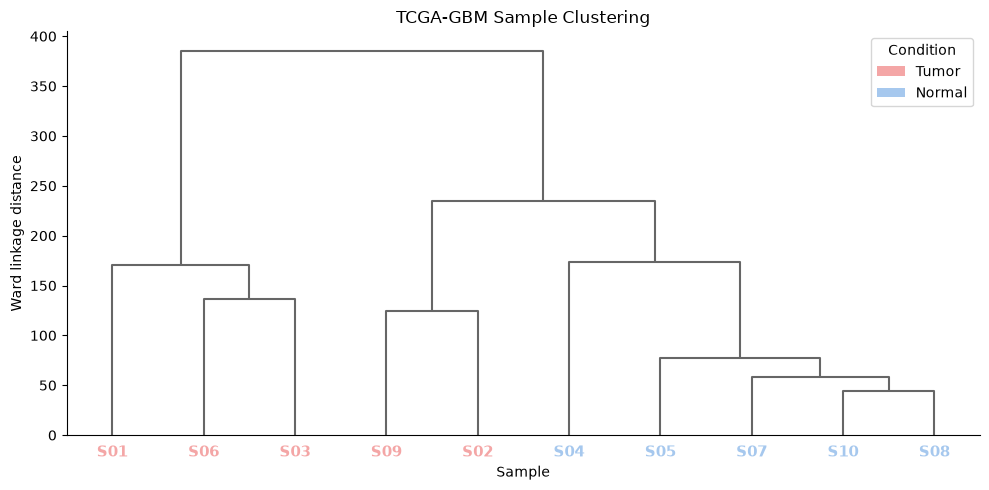

In [12]:
from scipy.cluster.hierarchy import linkage, dendrogram
from matplotlib.patches import Patch

# Cluster samples using all retained genes
linked = linkage(
    X,
    method="ward",
    metric="euclidean"
)

# Preserve sample labels from the previous plots
sample_labels = library_df["plot_label"].reindex(X.index)

label_conditions = dict(
    zip(sample_labels, metadata.loc[X.index, "condition"])
)

fig, ax = plt.subplots(figsize=(10, 5))

dendrogram(
    linked,
    labels=sample_labels.to_list(),
    leaf_rotation=0,
    leaf_font_size=11,
    link_color_func=lambda _: "#666666",
    ax=ax
)

# Color sample labels by condition
for label in ax.get_xticklabels():
    condition = label_conditions[label.get_text()]
    label.set_color(colors[condition])
    label.set_fontweight("bold")

ax.set_title("TCGA-GBM Sample Clustering")
ax.set_xlabel("Sample")
ax.set_ylabel("Ward linkage distance")
ax.spines[["top", "right"]].set_visible(False)

ax.legend(
    handles=[
        Patch(facecolor=color, label=condition)
        for condition, color in colors.items()
    ],
    title="Condition"
)

fig.tight_layout()
fig.savefig(
    FIGURES / "QC_Hierarchical_Clustering.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Hierarchical Clustering Interpretation

All five normal samples form a cluster. 

Tumor samples form two groups: S01/S06/S03 and S09/S02. 

Together, PCA and clustering show condition-associated expression differences alongside heterogenity among tumor samples. These exploratory results do not provide sufficient evidence to exclude any sample.

## 5- Export Filtered Counts and Metadata

The filtered raw count matrix and aligned sample metadata are saved for PyDESEQ in Notebook 3. A sample-label table is also saved to connect figure labels with original sample identifiers.

### Align metadata with the exported count matrix
metadata_qc = metadata.loc[filtered_counts.columns].copy()

filtered_counts.to_csv(DATA / "count_matrix_filtered.csv")
metadata_qc.to_csv(DATA / "metadata_qc.csv")

### Save figure-label mapping and library sizes
library_df.to_csv(DATA / "QC_sample_labels.csv")

print(f"Exported {filtered_counts.shape[0]:,} genes "
      f"across {filtered_counts.shape[1]} samples.")